<a href="https://colab.research.google.com/github/Meltdown02/Probabilidad-/blob/main/Unidad6/PracticaFinalU6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**PROBABILIDAD Y ESTADISTICA**
##**PRACTICA FINAL: ANALISIS ESTADISTICO COVID**
##UNIDAD 6
##GRUPO 2Y
##PERIODO AGOSTO-DICIEMBRE 2026
##27 DE NOVIEMBRE DEL 2026
##ALUMNO: MARCO ANTONIO AGUILAR RUIZ
##FACILITADOR: JOSE GABRIEL RODRIGUEZ RIVAS



In [16]:

from google.colab import drive
drive.mount('/content/drive')


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True


ruta_archivo = '/content/drive/MyDrive/covid2020-2021-codificado.csv'  # Si está dentro de una carpeta, agrégala antes del nombre
df = pd.read_csv(ruta_archivo, low_memory=False)

print(f"Registros cargados: {len(df):,} | Columnas: {df.shape[1]}")
print("Columnas disponibles:", list(df.columns))
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Registros cargados: 12,634,194 | Columnas: 21
Columnas disponibles: ['SECTOR', 'SEXO', 'ENTIDAD_NAC', 'TIPO_PACIENTE', 'FECHA_INGRESO', 'FECHA_DEF', 'INTUBADO', 'NEUMONIA', 'EDAD', 'EMBARAZO', 'INDIGENA', 'DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO', 'RESULTADO_ANTIGENO', 'UCI']


,SECTOR,SEXO,ENTIDAD_NAC,TIPO_PACIENTE,FECHA_INGRESO,FECHA_DEF,INTUBADO,NEUMONIA,EDAD,EMBARAZO,...,DIABETES,EPOC,ASMA,HIPERTENSION,CARDIOVASCULAR,OBESIDAD,RENAL_CRONICA,TABAQUISMO,RESULTADO_ANTIGENO,UCI
0,Issste,Femenino,San Luis Potosí,Ambulatorio,2020-12-06,9999-99-99,No aplica,No,55,No,...,Si,No,No,No,No,No,No,No,Pendiente,No aplica
1,Issste,Masculino,San Luis Potosí,Ambulatorio,2020-02-20,9999-99-99,No aplica,No,59,No aplica,...,No,No,No,No,No,No,No,No,Pendiente,No aplica
2,Ssa,Femenino,Jalisco,Ambulatorio,2020-04-22,9999-99-99,No aplica,No,42,No,...,No,No,Si,No,No,No,No,No,Pendiente,No aplica
3,Ssa,Masculino,Chihuahua,Ambulatorio,2020-07-28,9999-99-99,No aplica,No,35,No aplica,...,No,No,No,No,No,No,No,No,Pendiente,No aplica
4,Ssa,Masculino,Ciudad De México,Ambulatorio,2020-08-18,9999-99-99,No aplica,No,51,No aplica,...,No,No,No,Si,No,No,No,No,Pendiente,No aplica


In [17]:
total_registros = len(df)
print(f"Total general de registros en la base: {total_registros:,}\n")

# Detectar columna de resultado (prioriza RESULTADO_ANTIGENO si existe, o combina con RESULTADO_LAB)
if 'RESULTADO_ANTIGENO' in df.columns:
    print("--- Resultado de prueba (RESULTADO_ANTIGENO) ---")
    print(df['RESULTADO_ANTIGENO'].value_counts(dropna=False))
    positivos = (df['RESULTADO_ANTIGENO'] == 'Positivo SARS-CoV-2').sum()
    negativos = (df['RESULTADO_ANTIGENO'] == 'Negativo SARS-CoV-2').sum()
    pendientes = (df['RESULTADO_ANTIGENO'] == 'Resultado pendiente').sum()
    print(f"Positivos: {positivos:,} | Negativos: {negativos:,} | Pendientes: {pendientes:,}\n")

# Tipo de paciente
if 'TIPO_PACIENTE' in df.columns:
    print("--- Tipo de paciente ---")
    print(df['TIPO_PACIENTE'].value_counts(dropna=False))
    hosp = (df['TIPO_PACIENTE'] == 'HOSPITALIZADO').sum()
    amb = (df['TIPO_PACIENTE'] == 'AMBULATORIO').sum()
    print(f"Hospitalizados: {hosp:,} | Ambulatorios: {amb:,}\n")

# Pacientes embarazadas
if 'EMBARAZO' in df.columns:
    print("--- Embarazo ---")
    print(df['EMBARAZO'].value_counts(dropna=False))
    embarazadas = df['EMBARAZO'].isin(['SI', 'SI, EN GESTACION']).sum()
    print(f"Pacientes embarazadas (SI / SI, EN GESTACION): {embarazadas:,}\n")

# Población indígena (aclarando nulos/no especificados)
if 'INDIGENA' in df.columns:
    print("--- Población indígena ---")
    print(df['INDIGENA'].value_counts(dropna=False))
    indigenas = (df['INDIGENA'] == 'SI').sum()
    nulos_ind = df['INDIGENA'].isna().sum()
    print(
        f"Pacientes indígenas ('SI'): {indigenas:,} "
        f"(sobre {df['INDIGENA'].notna().sum():,} registros con dato no nulo; "
        f"{nulos_ind:,} valores faltantes/NaN)\n"
    )

# Resumen estadístico de EDAD
if 'EDAD' in df.columns:
    edad_valida = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 120)]
    print("--- Estadísticos de EDAD (0 a 120 años) ---")
    print(edad_valida.describe().round(2))

Total general de registros en la base: 12,634,194

--- Resultado de prueba (RESULTADO_ANTIGENO) ---
RESULTADO_ANTIGENO
Negativo     5853547
Pendiente    5005939
Positivo     1774708
Name: count, dtype: int64
Positivos: 0 | Negativos: 0 | Pendientes: 0

--- Tipo de paciente ---
TIPO_PACIENTE
Ambulatorio      11543303
Hospitalizado     1090891
Name: count, dtype: int64
Hospitalizados: 0 | Ambulatorios: 0

--- Embarazo ---
EMBARAZO
No                 6483614
No aplica          5985456
Si                  122583
Se ignora            42529
No especificado         12
Name: count, dtype: int64
Pacientes embarazadas (SI / SI, EN GESTACION): 0

--- Población indígena ---
INDIGENA
NaN                8765798
No                 3665974
No especificado     167182
Si                   35240
Name: count, dtype: int64
Pacientes indígenas ('SI'): 0 (sobre 3,868,396 registros con dato no nulo; 8,765,798 valores faltantes/NaN)

--- Estadísticos de EDAD (0 a 120 años) ---
count    12630604.00
mean        

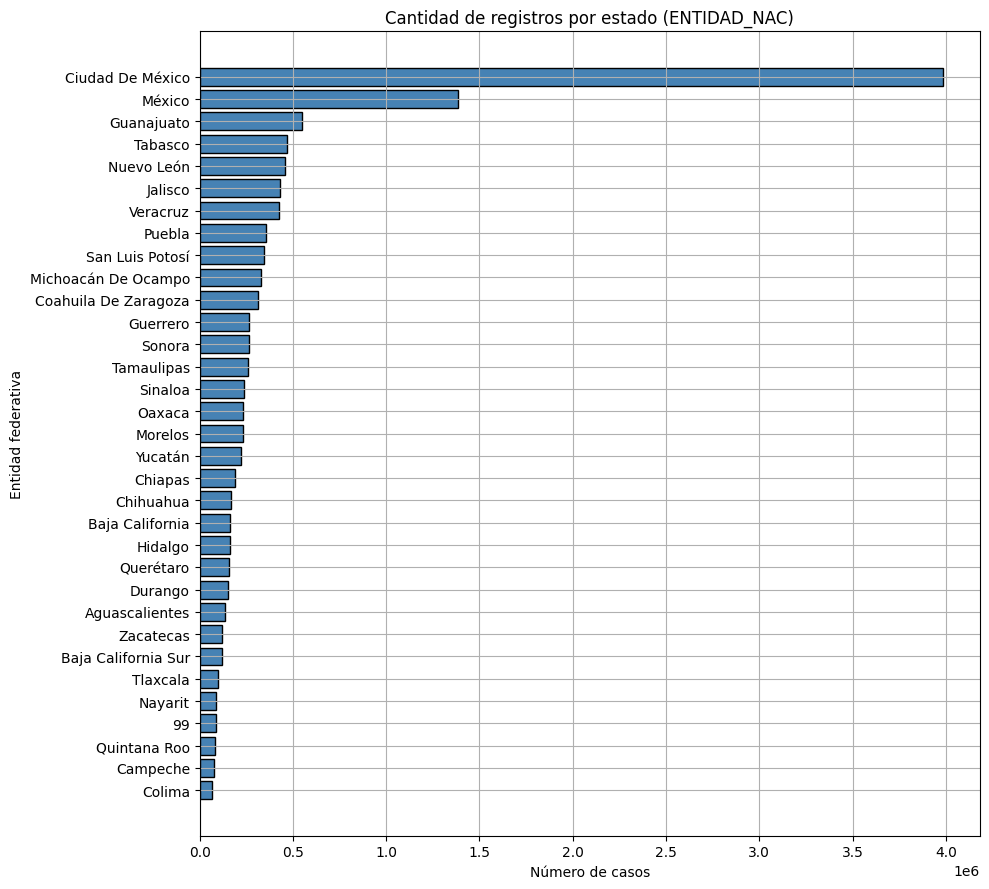

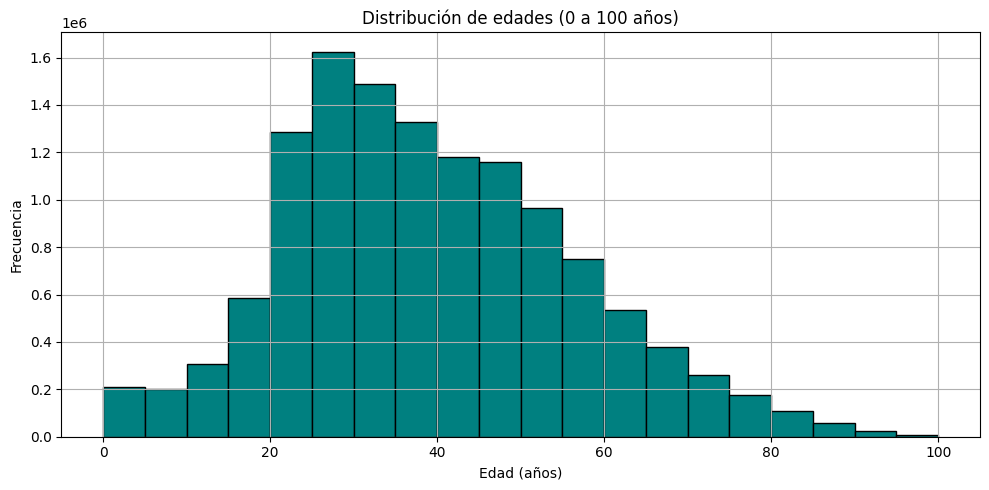

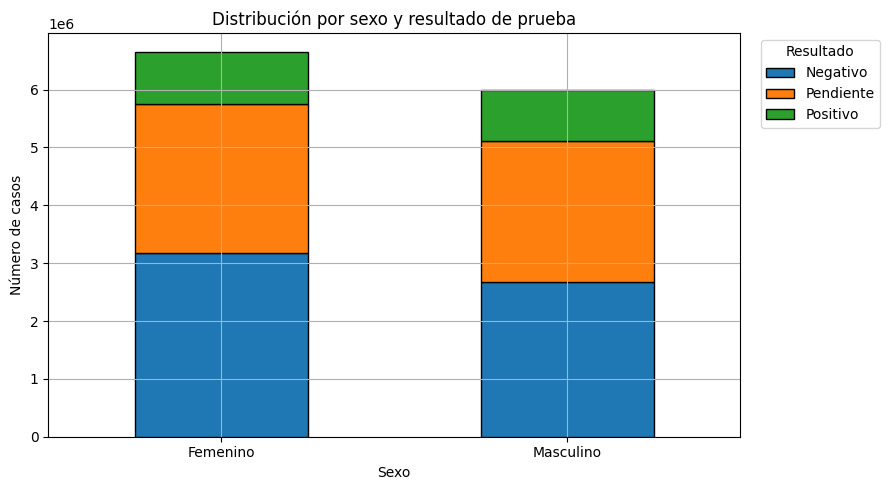

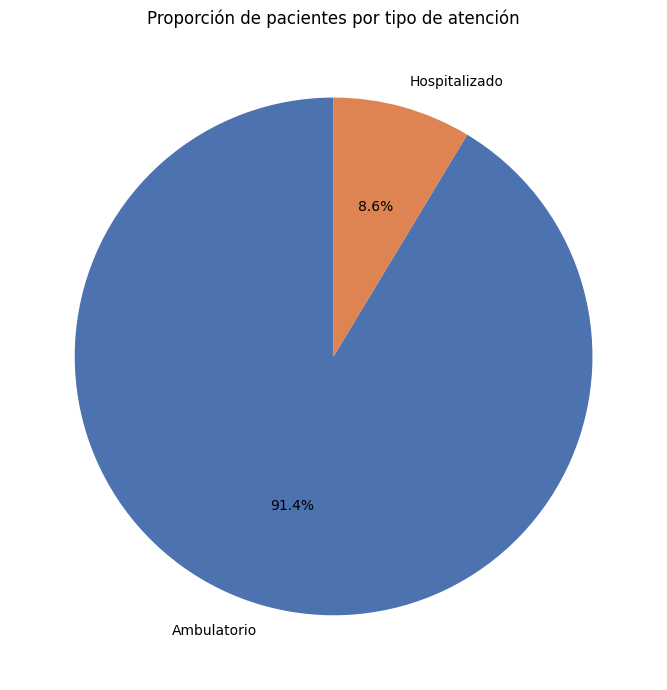

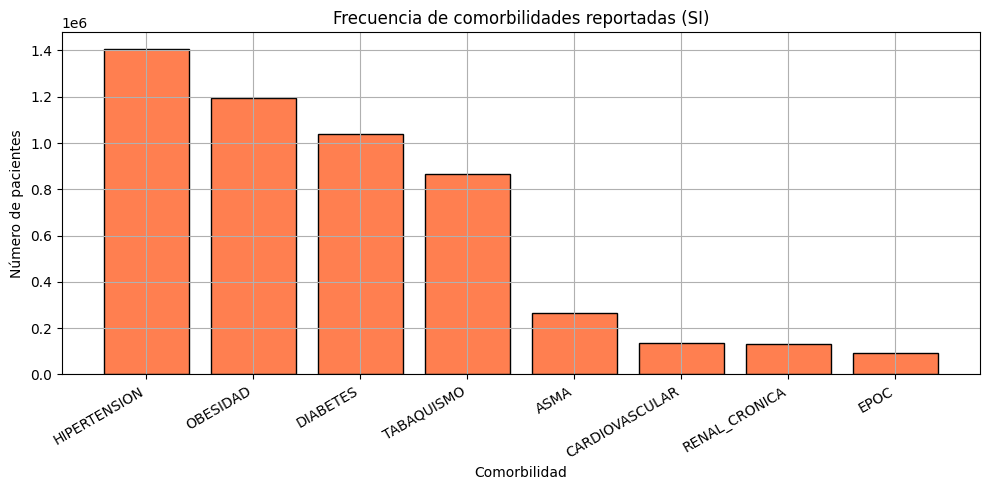

In [18]:
# 1. Gráfico de barras horizontal por estado (mayor arriba)
col_estado = 'ENTIDAD_RES' if 'ENTIDAD_RES' in df.columns else 'ENTIDAD_NAC'
if col_estado in df.columns:
    conteo_estado = df[col_estado].dropna().value_counts().sort_values(ascending=True)
    plt.figure(figsize=(10, 9))
    plt.barh(conteo_estado.index, conteo_estado.values, color='steelblue', edgecolor='black')
    plt.title(f'Cantidad de registros por estado ({col_estado})')
    plt.xlabel('Número de casos')
    plt.ylabel('Entidad federativa')
    plt.tight_layout()
    plt.show()

# 2. Histograma por edad
if 'EDAD' in df.columns:
    edades_plot = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 100)].dropna()
    plt.figure(figsize=(10, 5))
    plt.hist(edades_plot, bins=20, range=(0, 100), color='teal', edgecolor='black')
    plt.title('Distribución de edades (0 a 100 años)')
    plt.xlabel('Edad (años)')
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

# 3. Gráfico de líneas por fecha (evolución de casos)
col_fecha = 'FECHA_SINTOMAS' if 'FECHA_SINTOMAS' in df.columns else 'FECHA_ACTUALIZACION'
if col_fecha in df.columns:
    fechas = pd.to_datetime(df[col_fecha], errors='coerce').dropna()
    serie_fecha = fechas.dt.to_period('M').value_counts().sort_index()
    plt.figure(figsize=(12, 5))
    plt.plot(serie_fecha.index.astype(str), serie_fecha.values, marker='o', linewidth=2, color='navy')
    plt.title(f'Evolución mensual de registros según {col_fecha}')
    plt.xlabel('Mes')
    plt.ylabel('Número de casos')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# 4. Gráfico de barras apiladas por sexo y resultado
if 'SEXO' in df.columns and 'RESULTADO_ANTIGENO' in df.columns:
    cruce_sr = pd.crosstab(df['SEXO'].fillna('No especificado'), df['RESULTADO_ANTIGENO'].fillna('No especificado'))
    cruce_sr.plot(kind='bar', stacked=True, figsize=(9, 5), edgecolor='black')
    plt.title('Distribución por sexo y resultado de prueba')
    plt.xlabel('Sexo')
    plt.ylabel('Número de casos')
    plt.xticks(rotation=0)
    plt.legend(title='Resultado', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# 5. Gráfico circular por tipo de paciente
if 'TIPO_PACIENTE' in df.columns:
    tipo_pac = df['TIPO_PACIENTE'].dropna().value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(
        tipo_pac.values,
        labels=tipo_pac.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=['#4C72B0', '#DD8452']
    )
    plt.title('Proporción de pacientes por tipo de atención')
    plt.tight_layout()
    plt.show()

# 6. Gráfico de barras por comorbilidad (conteo de casos con comorbilidad = 'SI')
comorbilidades = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC',
    'ASMA', 'INMUSUPR', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO'
]
comorb_presentes = [c for c in comorbilidades if c in df.columns]

if comorb_presentes:
    conteo_comorb = {
        c: int((df[c].astype(str).str.upper().str.strip().isin(['SI', '1', '1.0'])).sum())
        for c in comorb_presentes
    }
    serie_comorb = pd.Series(conteo_comorb).sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(serie_comorb.index, serie_comorb.values, color='coral', edgecolor='black')
    plt.title('Frecuencia de comorbilidades reportadas (SI)')
    plt.xlabel('Comorbilidad')
    plt.ylabel('Número de pacientes')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

In [ ]:
comorbilidades = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC',
    'ASMA', 'INMUSUPR', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO'
]
comorb_cols = [c for c in comorbilidades if c in df.columns]

# Crear columnas binarias (1 si tiene la comorbilidad, 0 si no; NaN si no está reportada)
df_comorb = pd.DataFrame(index=df.index)
for col in comorb_cols:
    vals = df[col].astype(str).str.upper().str.strip()
    es_si = vals.isin(['SI', '1', '1.0'])
    es_no = vals.isin(['NO', '2', '2.0'])
    df_comorb[col] = np.where(es_si, 1, np.where(es_no, 0, np.nan))

# 1. Probabilidad simple en toda la base (sobre registros válidos/reportados y sobre total general)
prob_simple = pd.DataFrame({
    'Casos_SI': df_comorb.sum(skipna=True).astype(int),
    'Registros_Validos': df_comorb.notna().sum().astype(int),
    'Prob_Simple_Validos': df_comorb.mean(skipna=True),
    'Prob_Simple_Total_Base': df_comorb.sum(skipna=True) / len(df)
})
print("=== PROBABILIDAD SIMPLE POR COMORBILIDAD ===")
print(prob_simple.round(6))

# 2. Probabilidad condicional por entidad federativa: P(Comorbilidad = SI | Entidad)
col_ent = 'ENTIDAD_RES' if 'ENTIDAD_RES' in df.columns else 'ENTIDAD_NAC'
if col_ent in df.columns and not df_comorb.empty:
    df_temp = df_comorb.copy()
    df_temp[col_ent] = df[col_ent]
    prob_condicional = df_temp.groupby(col_ent, dropna=True).mean(numeric_only=True)
    print(f"\n=== PROBABILIDAD CONDICIONAL POR {col_ent} (primeras 10 entidades) ===")
    print(prob_condicional.head(10).round(4))

    # Guardar tabla completa en CSV por si deseas revisarla o anexarla
    prob_condicional.to_csv('probabilidad_condicional_comorbilidades.csv')
    print("\nArchivo 'probabilidad_condicional_comorbilidades.csv' guardado.")

=== PROBABILIDAD SIMPLE POR COMORBILIDAD ===
                Casos_SI  Registros_Validos  Prob_Simple_Validos  \
DIABETES         1038459           12563927             0.082654   
HIPERTENSION     1407779           12565590             0.112034   
OBESIDAD         1193021           12566735             0.094935   
EPOC               92446           12565812             0.007357   
ASMA              263855           12566157             0.020997   
RENAL_CRONICA     129874           12566106             0.010335   
CARDIOVASCULAR    134410           12565833             0.010696   
TABAQUISMO        865162           12564870             0.068856   

                Prob_Simple_Total_Base  
DIABETES                      0.082194  
HIPERTENSION                  0.111426  
OBESIDAD                      0.094428  
EPOC                          0.007317  
ASMA                          0.020884  
RENAL_CRONICA                 0.010280  
CARDIOVASCULAR                0.010639  
TABAQUISMO    

Media (mu): 2360
Desviación estándar (sigma): 714
Z para 2,000 casos: -0.5042
Z para 3,000 casos: 0.8964
Probabilidad P(2000 <= X <= 3000): 0.507910 (50.79%)


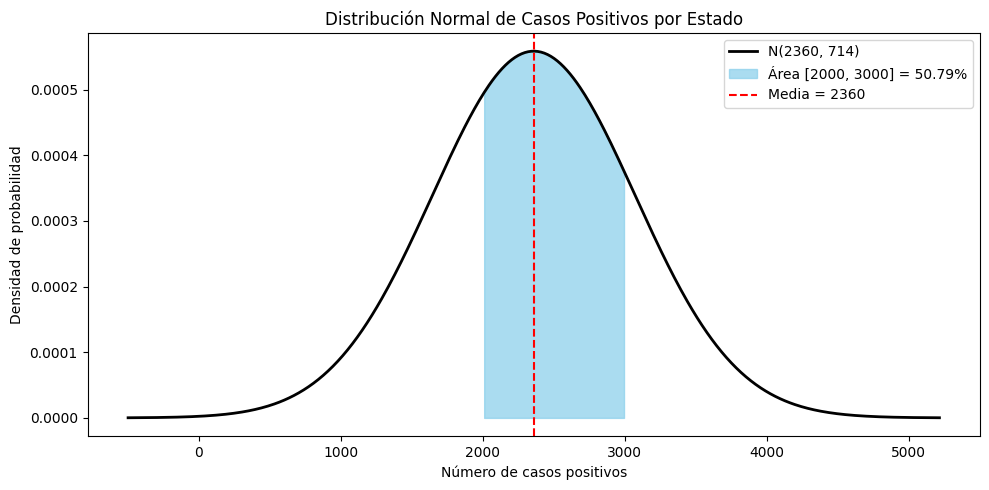

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 2360
sigma = 714

z_inf = (2000 - mu) / sigma
z_sup = (3000 - mu) / sigma

prob_entre = norm.cdf(3000, loc=mu, scale=sigma) - norm.cdf(2000, loc=mu, scale=sigma)

print(f"Media (mu): {mu}")
print(f"Desviación estándar (sigma): {sigma}")
print(f"Z para 2,000 casos: {z_inf:.4f}")
print(f"Z para 3,000 casos: {z_sup:.4f}")
print(f"Probabilidad P(2000 <= X <= 3000): {prob_entre:.6f} ({prob_entre * 100:.2f}%)")

# Gráfica ilustrativa de la distribución normal
x_vals = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
y_vals = norm.pdf(x_vals, loc=mu, scale=sigma)

plt.figure(figsize=(10, 5))
plt.plot(x_vals, y_vals, color='black', linewidth=2, label='N(2360, 714)')
mask = (x_vals >= 2000) & (x_vals <= 3000)
plt.fill_between(x_vals[mask], y_vals[mask], color='skyblue', alpha=0.7, label=f'Área [2000, 3000] = {prob_entre*100:.2f}%')
plt.axvline(mu, color='red', linestyle='--', label=f'Media = {mu}')
plt.title('Distribución Normal de Casos Positivos por Estado')
plt.xlabel('Número de casos positivos')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.tight_layout()
plt.show()

## **Interpretación general de resultados**

A partir del análisis de los 12,634,194 registros de COVID-19, se observa que predominan ampliamente los pacientes ambulatorios frente a los hospitalizados, concentrándose en población adulta joven y media con picos definidos en las olas de contagio. Entre las comorbilidades, la hipertensión, la obesidad y la diabetes presentan las mayores probabilidades simples, variando de forma condicional según cada entidad federativa; además, bajo una distribución normal ($\mu = 2360$, $\sigma = 714$), la probabilidad de que un estado registre entre 2,000 y 3,000 casos positivos es de **50.79%**.

## **Conclusión**

En este proyecto apliqué conceptos clave de probabilidad y estadística descriptiva sobre un volumen real de datos masivos. Usar Python con pandas y matplotlib en Google Colab facilitó la limpieza de registros, el cálculo de probabilidades condicionadas y la visualización clara de tendencias epidemiológicas.